In [1]:
import numpy as numpy
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df=pd.read_csv("C:\\Users\\yuvra\\Downloads\\customer_churn.csv")

In [11]:
df.head()

,age,income,credit_score,transactions_month,avg_purchase_value,days_since_last_login,tenure_months,num_products,gender,region,churn
0,56,NaN,770.887470,29,84.828689,143,90,1,Male,South,1
1,69,53051.954538,622.025467,41,133.943805,72,96,4,Female,East,1
2,46,38654.738821,665.727931,36,114.993023,155,88,3,Male,North,1
3,32,28666.194356,715.281358,29,153.875284,76,110,2,Male,South,0
4,60,40301.406736,NaN,27,115.391031,168,99,2,Male,East,1


In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   age                    1000 non-null   int64  
 1   income                 951 non-null    float64
 2   credit_score           950 non-null    float64
 3   transactions_month     1000 non-null   int64  
 4   avg_purchase_value     950 non-null    float64
 5   days_since_last_login  1000 non-null   int64  
 6   tenure_months          1000 non-null   int64  
 7   num_products           1000 non-null   int64  
 8   gender                 1000 non-null   str    
 9   region                 1000 non-null   str    
 10  churn                  1000 non-null   int64  
dtypes: float64(3), int64(6), str(2)
memory usage: 86.1 KB


In [13]:
df.isnull().sum()

age                       0
income                   49
credit_score             50
transactions_month        0
avg_purchase_value       50
days_since_last_login     0
tenure_months             0
num_products              0
gender                    0
region                    0
churn                     0
dtype: int64

In [14]:
df.describe()

,age,income,credit_score,transactions_month,avg_purchase_value,days_since_last_login,tenure_months,num_products,churn
count,1000.00000,951.000000,950.000000,1000.000000,950.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,43.81900,55354.417513,651.422837,29.842000,119.301574,182.155000,60.394000,3.129000,0.517000
std,14.99103,32708.500386,68.271995,5.453511,39.619144,104.205824,34.163166,1.410088,0.499961
min,18.00000,7271.860691,444.172796,15.000000,-7.068153,0.000000,1.000000,1.000000,0.000000
25%,31.00000,40959.853770,605.096009,26.000000,93.330104,88.000000,31.000000,2.000000,0.000000
50%,44.00000,51298.846812,650.746768,30.000000,119.585761,184.000000,61.000000,3.000000,1.000000
75%,56.00000,61285.465584,697.845647,33.000000,146.374081,273.250000,89.250000,4.000000,1.000000
max,69.00000,254852.478291,873.517530,49.000000,244.516408,364.000000,119.000000,5.000000,1.000000


<Axes: ylabel='income'>

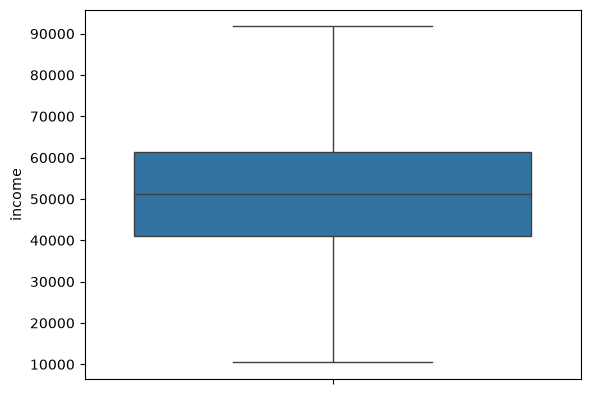

In [75]:
sns.boxplot(df['income'])

In [ ]:
# step 4: Data Preprocessing
# handled the missing value using median of all num columns

# 1: income
income_median=df['income'].median()
income_median=round(income_median,2)

# 2: credit score
credit_median=round(df['credit_score'].median(),2)

# avg_purchase_value
purchase_value_med=round(df['avg_purchase_value'].median(),2)

# credit score 
df['credit_score'].fillna(credit_median,inplace = True)

# income
df['income'].fillna(income_median,inplace = True)

# average purchase values
df['avg_purchase_value'].fillna(purchase_value_med,inplace = True)



C:\Users\yuvra\AppData\Local\Temp\ipykernel_11428\3332403063.py:15: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['credit_score'].fillna(credit_median,inplace = True)
C:\Users\yuvra\AppData\Local\Temp\ipykernel_11428\3332403063.py:18: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained a

0       84.828689
1      133.943805
2      114.993023
3      153.875284
4      115.391031
          ...    
995    149.322171
996     44.289513
997    132.459634
998     72.489390
999    104.107070
Name: avg_purchase_value, Length: 1000, dtype: float64

In [17]:
df.isnull().sum()

age                       0
income                   49
credit_score             50
transactions_month        0
avg_purchase_value       50
days_since_last_login     0
tenure_months             0
num_products              0
gender                    0
region                    0
churn                     0
dtype: int64

In [ ]:
# Handled the outlier

outlier_cols = ['income', 'credit_score', 'avg_purchase_value']

for col in num_columns:
    
    #find the Q1 and Q2
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    
    # find the IQR
    IQR =Q3 - Q1
    
    # find the upper bound and lower bound
    lower_bound = Q1 - 1.5*IQR
    
    upper_bound = Q3 + 1.5*IQR
    
    # handle the outlier
    df[col] = df[col].clip(lower=lower_bound, upper=upper_bound)

In [26]:
df.shape[0]

1000

<Axes: ylabel='credit_score'>

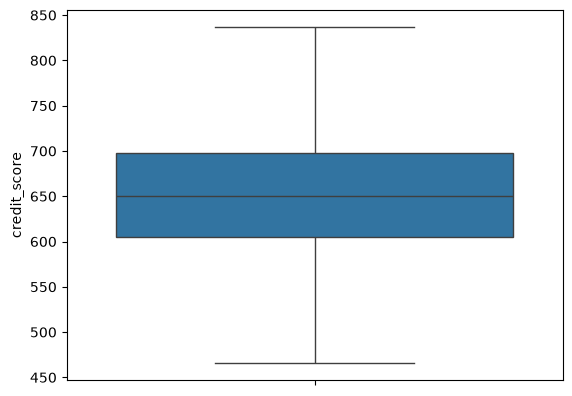

In [105]:
sns.boxplot(df['credit_score'])

In [107]:
df.head()

,age,income,credit_score,transactions_month,avg_purchase_value,days_since_last_login,tenure_months,num_products,gender,churn
0,56,NaN,770.887470,29.0,84.828689,143,90,1,1,1
1,69,53051.954538,622.025467,41.0,133.943805,72,96,4,0,1
2,46,38654.738821,665.727931,36.0,114.993023,155,88,3,1,1
3,32,28666.194356,715.281358,29.0,153.875284,76,110,2,1,0
4,60,40301.406736,NaN,27.0,115.391031,168,99,2,1,1


In [108]:
df.drop('region', axis=1, inplace=True, errors='ignore')

In [109]:
x = df.drop('churn',axis=1)
y = df['churn']

In [110]:
from sklearn.model_selection import train_test_split

x_train,x_test,y_train,y_test = train_test_split(x,y,test_size =0.2, random_state=42)

In [111]:
# Handle the categorical column
df['gender'] = df['gender'].replace({'male': 1, 'female': 0})


In [112]:
print(x_train.select_dtypes(include='object').columns)

Index(['gender'], dtype='str')


In [113]:
# Convert all categorical columns in x_train and x_test to numbers

x_train = pd.get_dummies(x_train, drop_first=True)
x_test = pd.get_dummies(x_test, drop_first=True)

# Make sure both datasets have the same columns
x_test = x_test.reindex(columns=x_train.columns, fill_value=0)

print(x_train.dtypes)

age                        int64
income                   float64
credit_score             float64
transactions_month       float64
avg_purchase_value       float64
days_since_last_login      int64
tenure_months              int64
num_products               int64
gender_1                    bool
dtype: object


In [114]:
# Handle missing values
x_train = x_train.fillna(0)
x_test = x_test.fillna(0)

In [115]:
# Step 7: Model Building

from sklearn.linear_model import LogisticRegression

# Create the instance of model
LR = LogisticRegression(max_iter=1000)

# Train model
model=LR.fit(x_train, y_train)

# Prediction on Testing
y_pred = model.predict(x_test)

print(y_pred)

[1 1 1 0 0 1 0 1 1 1 1 1 0 1 1 0 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1
 1 1 0 0 1 1 0 1 0 1 1 0 0 1 0 1 1 1 0 1 0 1 0 0 1 0 1 0 0 1 1 1 0 1 1 0 1
 1 1 0 0 0 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 1 1 0 1 0 1 1 1 1 0 1 1
 1 1 0 1 1 1 1 1 1 1 0 1 1 1 0 1 1 1 1 1 1 1 0 1 1 0 1 1 1 1 1 1 1 1 1 1 1
 1 0 0 1 1 1 1 0 1 1 1 0 1 1 1 0 1 1 1 1 0 1 1 0 1 0 0 1 0 1 0 0 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 0 0 1]


c:\Users\yuvra\anaconda3\envs\dsenv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [116]:
print(x_train.isnull().sum().sum())
print(x_test.isnull().sum().sum())

0
0


In [119]:
# step 8: Model Evaluation metrics
from sklearn.metrics import accuracy_score

# find accuracy
ac = accuracy_score(y_test,y_pred)
print("Accuracy Of Model",ac)

Accuracy Of Model 0.495
